# EmoView - Emotion Classification with DAIR-AI Emotion

**Applied Machine Learning final project**

**Authors:** Rakhmettula Ramazan and Agzam Sayat

**Group:** BDA-2406

## Objective
**Research question:** How accurately can TF-IDF with Logistic Regression and a fine-tuned DistilBERT model classify six emotions in the DAIR-AI Emotion dataset?

The project compares a classical text-classification baseline with a pretrained transformer. Both models predict one of six emotions: sadness, joy, love, anger, fear, and surprise.

The workflow includes data cleaning, stratified splitting, feature extraction or tokenization, training, validation-based model selection, and final evaluation on held-out test data. Performance is assessed using accuracy, weighted precision, weighted recall, weighted F1, macro F1, and confusion matrices.

The original proposal focused on customer feedback. This experiment instead evaluates English Twitter messages, so its results do not directly establish performance on customer reviews.

In [ ]:
!pip install -q transformers "accelerate>=0.26,<2"

In [ ]:
import re
import time
import unicodedata
from pathlib import Path
from urllib.request import urlretrieve
from shutil import make_archive

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import Dataset
from transformers import pipeline
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, TrainingArguments, Trainer,
    EarlyStoppingCallback, set_seed
)

In [ ]:
SEED=42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
LABELS=['sadness','joy','love','anger','fear','surprise']
N_CLASSES=len(LABELS)
OUT=Path('emoview_dair_outputs');
OUT.mkdir(exist_ok=True)

BASE_MODEL = 'distilbert/distilbert-base-uncased'
MAX_LENGTH = 128
EPOCHS = 3
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 64
GRADIENT_ACCUMULATION = 2
LEARNING_RATE = 2e-5

sns.set_theme(style='whitegrid',context='notebook')
pd.set_option('display.max_colwidth',100)

def normalize_text(text):
    text = unicodedata.normalize('NFKC', str(text))
    return re.sub(r'\s+', ' ', text).strip().lower()

def finish_figure(name):
    plt.tight_layout()
    plt.savefig(OUT / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()

def metrics(y_true, y_pred):
    precision, recall, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=range(N_CLASSES), average='weighted', zero_division=0
    )
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'weighted_precision': precision,
        'weighted_recall': recall,
        'weighted_f1': weighted_f1,
        'macro_f1': f1_score(y_true, y_pred, labels=range(N_CLASSES), average='macro', zero_division=0)
    }

## Dataset
The experiment uses the large **unsplit configuration of DAIR-AI Emotion**, containing 416,809 rows. The Parquet file is loaded with pandas and contains two fields: `text`, representing an English Twitter message, and `label`, representing its emotion category.

The label mapping is: 0 = sadness, 1 = joy, 2 = love, 3 = anger, 4 = fear, and 5 = surprise. No missing values were found in either column.

The dataset contains automatically obtained emotion annotations, which may include noise or ambiguity. It provides no separate sarcasm labels, and neutral and frustration are not included in its label inventory.

In [ ]:
DATA_FILE = Path('emotion_full.parquet')
DATA_URL = (
    'https://huggingface.co/datasets/dair-ai/emotion/resolve/main/'
    'unsplit/train-00000-of-00001.parquet'
)

if not DATA_FILE.exists():
    print('Downloading the large Parquet file...')
    urlretrieve(DATA_URL, DATA_FILE)

raw = pd.read_parquet(DATA_FILE)
if not {'text', 'label'}.issubset(raw.columns):
    raise ValueError('The file must contain text and label columns.')
if len(raw) < 100000:
    raise ValueError('This is not the large dataset. Use the unsplit Parquet with at least 100,000 rows.')

print('Source shape:', raw.shape)
display(raw.head())
display(pd.DataFrame({'label': range(N_CLASSES), 'emotion': LABELS}))
display(raw[['text', 'label']].isna().sum().to_frame('missing'))

Source shape: (416809, 2)


,text,label
0,i feel awful about it too because it s my job to get him in a position to succeed and it just di...,0
1,im alone i feel awful,0
2,ive probably mentioned this before but i really do feel proud of myself for actually keeping up ...,1
3,i was feeling a little low few days back,0
4,i beleive that i am much more sensitive to other peoples feelings and tend to be more compassionate,2


,label,emotion
0,0,sadness
1,1,joy
2,2,love
3,3,anger
4,4,fear
5,5,surprise


,missing
text,0
label,0


## Cleaning

Text is normalized using Unicode NFKC normalization, lowercase conversion, and whitespace standardization. Normalized text is used to identify repeated messages.

Rows with missing or empty text or invalid labels are excluded. When the same normalized text has multiple emotion labels, all rows belonging to that conflicting group are removed. Repeated texts with a consistent label are reduced to one observation.

This cleaning policy is applied before splitting. It prevents identical normalized texts from appearing in different subsets, but it also removes ambiguous cases and changes the population being evaluated.

In [ ]:
valid = raw['text'].notna() & raw['label'].isin(range(N_CLASSES))
valid &= raw['text'].fillna('').astype(str).str.strip().ne('')

data = raw.loc[valid, ['text', 'label']].copy()
data['source_row'] = data.index
data['label'] = data['label'].astype(int)
data['normalized_text'] = data['text'].map(normalize_text)
labels_per_text = data.groupby('normalized_text')['label'].nunique()
conflicting_texts = labels_per_text[labels_per_text > 1].index
conflict_mask = data['normalized_text'].isin(conflicting_texts)
conflicting_rows = int(conflict_mask.sum())

consistent = data.loc[~conflict_mask].copy()
duplicate_rows = int(consistent['normalized_text'].duplicated().sum())
df = consistent.drop_duplicates('normalized_text').reset_index(drop=True)

audit = pd.DataFrame({
    'count': [len(raw), int((~valid).sum()), len(conflicting_texts),
              conflicting_rows, duplicate_rows, len(df)]
}, index=['source_rows', 'invalid_rows_removed', 'conflicting_text_groups',
          'conflicting_rows_removed', 'repeated_consistent_rows_removed', 'usable_unique_texts'])
display(audit)

,count
source_rows,416809
invalid_rows_removed,0
conflicting_text_groups,22295
conflicting_rows_removed,44650
repeated_consistent_rows_removed,632
usable_unique_texts,371527


No invalid rows were identified. Cleaning removed 44,650 rows from 22,295 conflicting text groups and another 632 repeated rows with consistent labels. The resulting dataset contains **371,527 unique normalized texts**.

All remaining observations are used in the experiment. No additional sampling or row limit is applied. The reported results therefore describe the cleaned dataset rather than the complete original collection.

## Data Preprocessing

The cleaned dataset is divided into training, validation, and test subsets using an approximately 80%/10%/10% stratified split with `random_state=42`. Stratification preserves similar emotion proportions across the subsets.

The training set contains 297,221 observations, while validation and test each contain 37,153 observations. Assertions verify that the subsets contain no identical normalized texts.

TF-IDF is fitted only on training data. DistilBERT receives tokenized text and is fine-tuned only on training observations. Validation data determines the selected checkpoint and final model; test data is reserved for the final comparison.

In [ ]:
train, remaining = train_test_split(
    df, test_size=0.20, stratify=df['label'], random_state=SEED
)
validation, test = train_test_split(
    remaining, test_size=0.50, stratify=remaining['label'], random_state=SEED
)
train = train.reset_index(drop=True)
val_eval = validation.reset_index(drop=True)
test_eval = test.reset_index(drop=True)

assert set(train['normalized_text']).isdisjoint(val_eval['normalized_text'])
assert set(train['normalized_text']).isdisjoint(test_eval['normalized_text'])
assert set(val_eval['normalized_text']).isdisjoint(test_eval['normalized_text'])
assert len(train) + len(val_eval) + len(test_eval) == len(df)
assert len(train) >= 100000

split_summary = pd.DataFrame({
    'rows': [len(train), len(val_eval), len(test_eval)]
}, index=['train', 'validation', 'test'])
display(split_summary)

parts = {'train': train, 'validation': val_eval, 'test': test_eval}
distribution = pd.DataFrame({
    name: frame['label'].value_counts().reindex(range(N_CLASSES), fill_value=0)
    for name, frame in parts.items()
})
distribution.index = LABELS
display(distribution)

y_train = train['label'].to_numpy()
y_val = val_eval['label'].to_numpy()
y_test = test_eval['label'].to_numpy()

,rows
train,297221
validation,37153
test,37153


,train,validation,test
sadness,92835,11604,11605
joy,103491,12937,12936
love,19502,2438,2438
anger,41862,5232,5233
fear,31667,3959,3958
surprise,7864,983,983


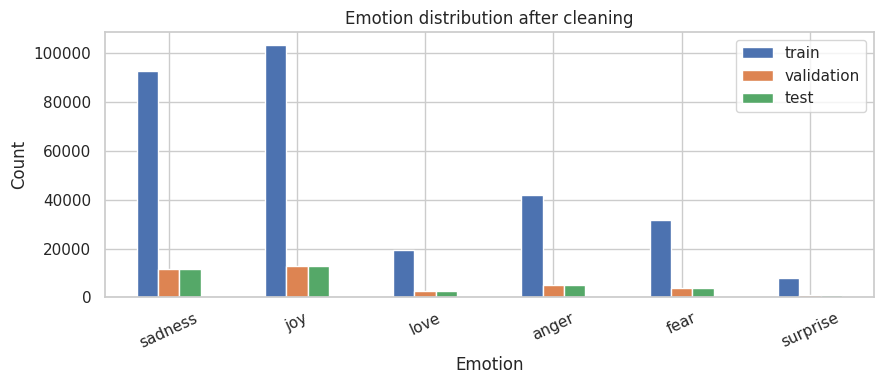

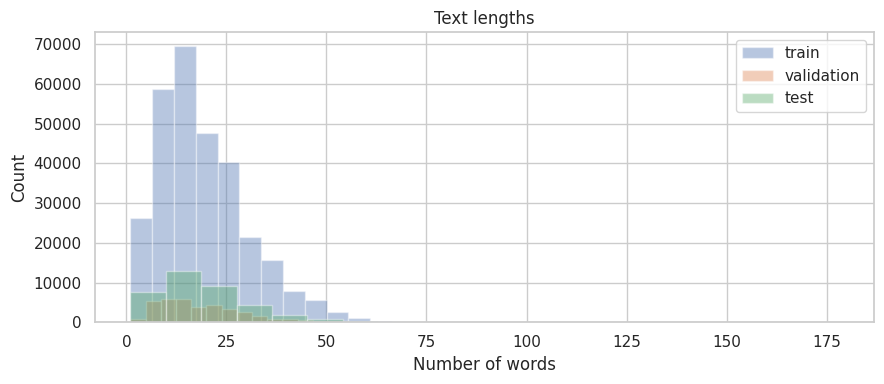

In [ ]:
distribution.plot.bar(figsize=(9, 4), rot=25)
plt.xlabel('Emotion')
plt.ylabel('Count')
plt.title('Emotion distribution after cleaning')
finish_figure('01_emotion_distribution')

plt.figure(figsize=(9, 4))
for name, frame in parts.items():
    plt.hist(frame['text'].str.split().str.len(), bins=20, alpha=0.4, label=name)
plt.xlabel('Number of words')
plt.ylabel('Count')
plt.title('Text lengths')
plt.legend()
finish_figure('02_text_lengths')

The class distribution is imbalanced: joy and sadness are the most frequent emotions, while surprise is the least frequent. Similar proportions are maintained across all three subsets.

Weighted F1 summarizes performance while accounting for class frequency. Macro F1 and per-class precision and recall are also reported to assess performance on less frequent emotions.

Most messages are relatively short, although the word-count distribution has a longer right tail. Text length is shown here in whitespace-separated words; DistilBERT uses subword tokens instead.

## Baseline: TF-IDF + Logistic Regression

The baseline combines TF-IDF text representations with Logistic Regression in a scikit-learn pipeline. TF-IDF uses unigrams and bigrams, a maximum of 50,000 features, a minimum document frequency of two, and sublinear term-frequency scaling.

Logistic Regression uses `C=4.0`, balanced class weights, and a maximum of 500 iterations. Balanced weights give greater importance to observations from less frequent classes during training.

Stop words are retained. Word order is represented only through the selected n-grams, making this model a useful comparison with the contextual representations learned by DistilBERT.

In [ ]:
baseline = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2), min_df=2, max_features=50000,
        sublinear_tf=True, dtype=np.float32, stop_words=None
    )),
    ('classifier', LogisticRegression(
        C=4.0, class_weight='balanced', max_iter=500, random_state=SEED
    ))
])

start = time.perf_counter()
baseline.fit(train['normalized_text'], y_train)
baseline_seconds = time.perf_counter() - start
assert np.array_equal(baseline.classes_, np.arange(N_CLASSES))

baseline_val_pred = baseline.predict(val_eval['normalized_text'])
models = {
    'TF-IDF + Logistic Regression': {'kind': 'sklearn', 'model': baseline}
}
validation_rows = [{
    'model': 'TF-IDF + Logistic Regression',
    'fit_seconds': baseline_seconds,
    **metrics(y_val, baseline_val_pred)
}]
display(pd.DataFrame(validation_rows).round(4))
print('Learned TF-IDF features:', len(baseline.named_steps['tfidf'].vocabulary_))
print('Baseline training rows:', len(train))

,model,fit_seconds,accuracy,weighted_precision,weighted_recall,weighted_f1,macro_f1
0,TF-IDF + Logistic Regression,134.7176,0.9697,0.9702,0.9697,0.9698,0.9625


Learned TF-IDF features: 50000
Baseline training rows: 297221


The baseline achieved **96.97% validation accuracy**, **0.9698 weighted F1**, and **0.9625 macro F1**. Training on all 297,221 training observations took approximately 86 seconds in this run.

These results indicate that local words and phrases provide strong predictive signals in the cleaned dataset. The slightly lower macro F1 suggests some variation in performance across emotion classes.

## DistilBERT

DistilBERT is used as the contextual text-classification model. The experiment starts from `distilbert-base-uncased` and fine-tunes its pretrained encoder together with a classification head for the six emotion classes.

Unlike TF-IDF, DistilBERT represents words in their surrounding context. The comparison evaluates whether this additional contextual modeling improves classification on the same data split.

### Tokenizer
The pretrained tokenizer converts each message into subword token IDs and attention masks. The maximum sequence length is set to 128 tokens, and dynamic padding adjusts each batch to the longest sequence within that batch.

The longest training sequence contains 121 tokens, while the longest validation sequence contains 86. Therefore, no training or validation messages are truncated at the selected limit. All observations in both subsets are retained.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)

class EmotionDataset(Dataset):
    def __init__(self, frame, name):
        texts = frame['text'].tolist()
        self.labels = frame['label'].astype(int).tolist()
        self.encodings = tokenizer(texts, truncation=False, padding=False)
        lengths = [len(ids) for ids in self.encodings['input_ids']]
        truncated = sum(length > MAX_LENGTH for length in lengths)
        print(name, '| rows:', len(texts), '| longest subword sequence:', max(lengths),
              '| rows truncated to', MAX_LENGTH, ':', truncated)
        if truncated:
            self.encodings = tokenizer(
                texts, truncation=True, max_length=MAX_LENGTH, padding=False
            )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        item = {key: value[index] for key, value in self.encodings.items()}
        item['labels'] = self.labels[index]
        return item

train_dataset = EmotionDataset(train, 'train')
val_dataset = EmotionDataset(val_eval, 'validation')
tokenizer.model_max_length = MAX_LENGTH
assert len(train_dataset) == len(train)
assert len(val_dataset) == len(val_eval)
print('No row limit is applied. Padding is performed per batch.')

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

train | rows: 297221 | longest subword sequence: 121 | rows truncated to 128 : 0
validation | rows: 37153 | longest subword sequence: 86 | rows truncated to 128 : 0
No row limit is applied. Padding is performed per batch.


### Fine-tuning
DistilBERT is fine-tuned for three epochs using AdamW, a learning rate of 0.00002, and weight decay of 0.01. Learning-rate warmup covers the first 10% of the planned optimizer steps.

The training batch size is 16, with gradient accumulation over two batches, giving an effective batch size of 32 on a single GPU. Evaluation uses batches of 64. FP16 mixed precision is enabled for GPU training.

Validation and checkpoint saving occur after each epoch. The checkpoint with the highest validation weighted F1 is restored at the end. Early stopping is configured with a patience of two evaluations.

In [ ]:
set_seed(SEED)
transformer = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL,
    num_labels=N_CLASSES,
    id2label=dict(enumerate(LABELS)),
    label2id={label: i for i, label in enumerate(LABELS)},
    use_safetensors=True
)

def compute_transformer_metrics(eval_prediction):
    logits, labels = eval_prediction
    return metrics(labels, logits.argmax(axis=1))

training_args = TrainingArguments(
    output_dir=str(OUT / 'distilbert_checkpoints'),
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    warmup_steps=0.1,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,
    dataloader_drop_last=False,
    fp16=True,
    bf16=False,
    optim='adamw_torch',
    eval_strategy='epoch',
    save_strategy='epoch',
    logging_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='weighted_f1',
    greater_is_better=True,
    save_total_limit=2,
    report_to='none',
    push_to_hub=False,
    seed=SEED,
    data_seed=SEED
)

trainer = Trainer(
    model=transformer,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8),
    compute_metrics=compute_transformer_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

start = time.perf_counter()
trainer.train()
transformer_seconds = time.perf_counter() - start

models['DistilBERT'] = {
    'kind': 'transformer', 'model': trainer.model, 'tokenizer': tokenizer
}
val_output = trainer.predict(val_dataset)
validation_rows.append({
    'model': 'DistilBERT',
    'fit_seconds': transformer_seconds,
    **metrics(y_val, val_output.predictions.argmax(axis=1))
})
print('DistilBERT training completed. The best validation checkpoint is loaded.')

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1
1,0.302318,0.018935,0.994348,0.994375,0.994348,0.994351,0.991726
2,0.029137,0.017764,0.994967,0.994996,0.994967,0.994972,0.992120
3,0.014442,0.020220,0.995397,0.995419,0.995397,0.995400,0.993241


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT training completed. The best validation checkpoint is loaded.


Training completed all three epochs in approximately **41.4 minutes**. Validation weighted F1 increased from 0.9940 after the first epoch to 0.9950 after the second and 0.9955 after the third.

The third checkpoint was selected because it achieved the highest validation weighted F1. Test performance was not used to select the checkpoint.

### Learning curves

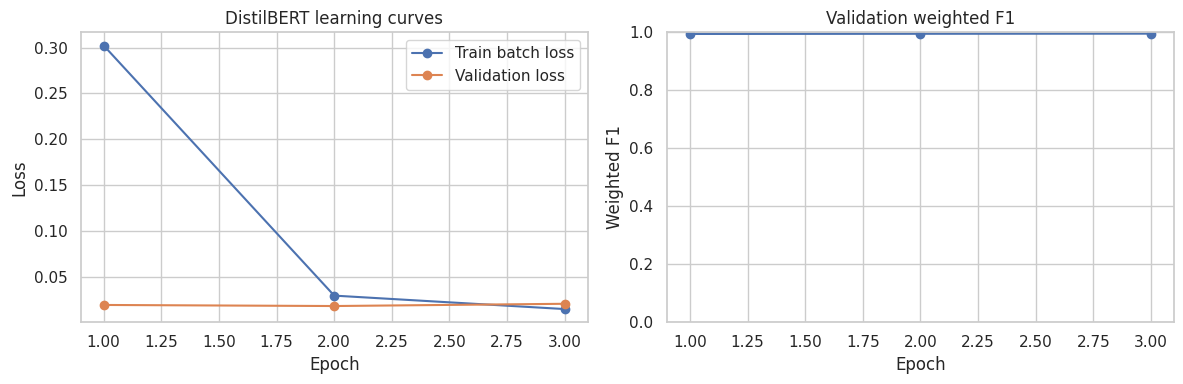

In [ ]:
train_history = pd.DataFrame([row for row in trainer.state.log_history if 'loss' in row])
val_history = pd.DataFrame([row for row in trainer.state.log_history if 'eval_loss' in row])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train_history['epoch'], train_history['loss'], marker='o', label='Train batch loss')
axes[0].plot(val_history['epoch'], val_history['eval_loss'], marker='o', label='Validation loss')
axes[0].set(xlabel='Epoch', ylabel='Loss', title='DistilBERT learning curves')
axes[0].legend()
axes[1].plot(val_history['epoch'], val_history['eval_weighted_f1'], marker='o')
axes[1].set(xlabel='Epoch', ylabel='Weighted F1', title='Validation weighted F1', ylim=(0, 1))
finish_figure('03_distilbert_learning_curves')

Training loss decreased across the three epochs. Validation loss reached its minimum after the second epoch and increased slightly after the third, while validation weighted F1 continued to improve.

This is possible because cross-entropy loss considers the probabilities assigned to classes, whereas F1 depends on the final predicted labels. The increase in validation loss may indicate less favorable confidence estimates for some examples, despite improved classification.

Training loss is averaged during each epoch, while validation loss is measured after the epoch. Their values are therefore not directly comparable under identical evaluation conditions.

### Save the model

In [ ]:
MODEL_DIR = Path("emoview_model")

trainer.model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

archive = make_archive(
    "emoview_model", "zip",
    root_dir=MODEL_DIR.parent,
    base_dir=MODEL_DIR.name,
)
print(f"Model saved to: {MODEL_DIR.resolve()}")
print(f"Download this archive: {archive}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/emoview_model
Download this archive: /content/emoview_model.zip


## Probability function

A shared function returns class probabilities from either model using the same interface. For Logistic Regression, the pipeline applies TF-IDF and calls `predict_proba`. For DistilBERT, text is tokenized, processed in batches, and the output logits are converted into probabilities using softmax.

The class with the highest probability becomes the predicted emotion. Its probability is reported as a confidence score, which should not be interpreted as a calibrated guarantee of correctness.

This function is used for test evaluation, error analysis, and predictions on new text.

In [ ]:
def predict_entry(entry, texts, batch_size=64):
    if isinstance(texts, str):
        texts = [texts]
    texts = list(texts)
    if not texts or any(not isinstance(text, str) or not text.strip() for text in texts):
        raise ValueError('Provide one or more non-empty text strings.')
    model = entry['model']

    if entry['kind'] == 'sklearn':
        return model.predict_proba([normalize_text(text) for text in texts])

    model.eval()
    model_tokenizer = entry['tokenizer']
    device = next(model.parameters()).device
    probabilities = []
    with torch.inference_mode():
        for start in range(0, len(texts), batch_size):
            inputs = model_tokenizer(
                texts[start:start + batch_size],
                padding=True, truncation=True,
                max_length=model_tokenizer.model_max_length,
                return_tensors='pt'
            )
            inputs = {key: value.to(device) for key, value in inputs.items()}
            logits = model(**inputs).logits
            probabilities.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(probabilities)

## Freeze the winner

In [ ]:
validation_table = pd.DataFrame(validation_rows).sort_values(
    'weighted_f1', ascending=False
).reset_index(drop=True)
BEST_NAME = validation_table.loc[0, 'model']
BEST = models[BEST_NAME]
print('Selected on validation:', BEST_NAME)
display(validation_table.round(4))

Selected on validation: DistilBERT


,model,fit_seconds,accuracy,weighted_precision,weighted_recall,weighted_f1,macro_f1
0,DistilBERT,2419.0548,0.9954,0.9954,0.9954,0.9954,0.9932
1,TF-IDF + Logistic Regression,134.7176,0.9697,0.9702,0.9697,0.9698,0.9625


DistilBERT was selected using validation weighted F1: **0.9955**, compared with **0.9698** for TF-IDF with Logistic Regression.

The selection rule was fixed before final test evaluation. Both models are evaluated on the test set for comparison, but the test scores do not change the validation-selected winner.

## Comparison

In [ ]:
test_rows = []
test_probs = {}
reports = {}
for name, entry in models.items():
    probabilities = predict_entry(entry, test_eval['text'])
    predictions = probabilities.argmax(axis=1)
    test_probs[name] = probabilities
    test_rows.append({
        'model': name,
        'selected_on_validation': name == BEST_NAME,
        **metrics(y_test, predictions)
    })
    reports[name] = pd.DataFrame(classification_report(
        y_test, predictions, labels=range(N_CLASSES), target_names=LABELS,
        output_dict=True, zero_division=0
    )).T

test_table = pd.DataFrame(test_rows)
display(test_table.round(4))

,model,selected_on_validation,accuracy,weighted_precision,weighted_recall,weighted_f1,macro_f1
0,TF-IDF + Logistic Regression,False,0.9695,0.9700,0.9695,0.9696,0.9614
1,DistilBERT,True,0.9958,0.9958,0.9958,0.9958,0.9937


In [ ]:
for name in models:
    print(name)
    display(reports[name].loc[LABELS].round(4))

final_probs = test_probs[BEST_NAME]
final_pred = final_probs.argmax(axis=1)
final_metrics = metrics(y_test, final_pred)
report = reports[BEST_NAME]
np.testing.assert_allclose(final_probs.sum(axis=1), 1, atol=1e-5)

TF-IDF + Logistic Regression


,precision,recall,f1-score,support
sadness,0.9821,0.9666,0.9742,11605.0
joy,0.9861,0.9678,0.9769,12936.0
love,0.9267,0.9848,0.9549,2438.0
anger,0.9528,0.9715,0.9621,5233.0
fear,0.9463,0.9699,0.9580,3958.0
surprise,0.9116,0.9756,0.9425,983.0


DistilBERT


,precision,recall,f1-score,support
sadness,0.9980,0.9973,0.9977,11605.0
joy,0.9977,0.9982,0.9980,12936.0
love,0.9996,0.9996,0.9996,2438.0
anger,0.9893,0.9925,0.9909,5233.0
fear,0.9941,0.9846,0.9893,3958.0
surprise,0.9761,0.9980,0.9869,983.0


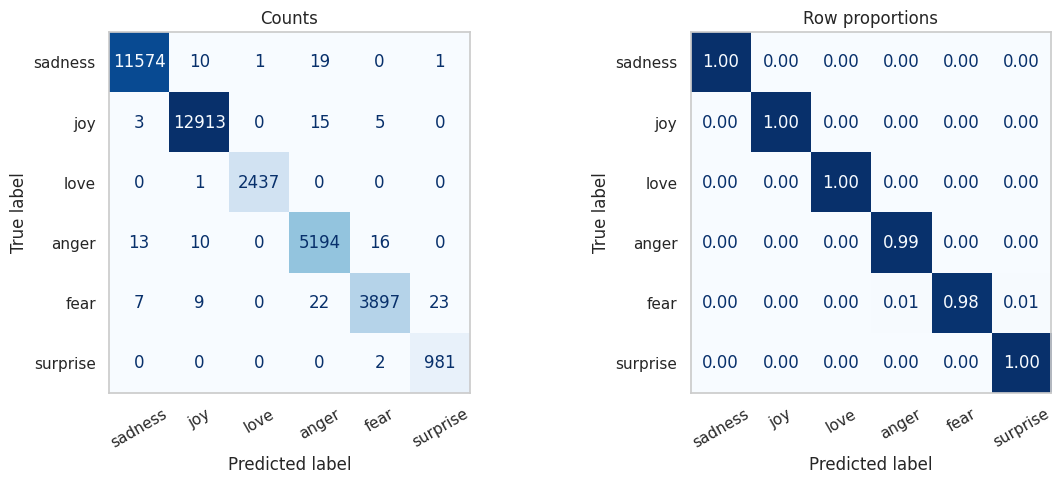

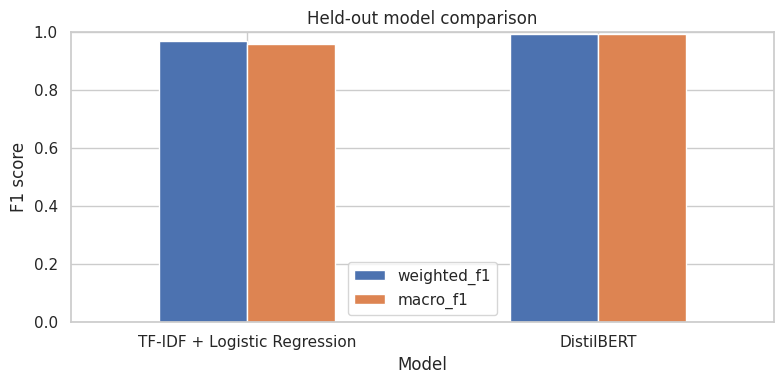

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, normalization in zip(axes, [None, 'true']):
    ConfusionMatrixDisplay.from_predictions(
        y_test, final_pred, labels=range(N_CLASSES), display_labels=LABELS,
        normalize=normalization, values_format='d' if normalization is None else '.2f',
        xticks_rotation=30, cmap='Blues', colorbar=False, ax=ax
    )
    ax.grid(False)
    ax.set_title('Counts' if normalization is None else 'Row proportions')
finish_figure('04_confusion_matrices')

test_table.set_index('model')[['weighted_f1', 'macro_f1']].plot.bar(figsize=(8, 4), rot=0)
plt.ylabel('F1 score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.title('Held-out model comparison')
finish_figure('05_model_comparison')

On the 37,153 held-out test observations, TF-IDF with Logistic Regression achieved **96.95% accuracy**, **0.9696 weighted F1**, and **0.9614 macro F1**. DistilBERT achieved **99.58% accuracy**, **0.9958 weighted F1**, and **0.9937 macro F1**.

DistilBERT improved accuracy by approximately 2.66 percentage points. Its predictions were incorrect for 146 test observations. The close agreement between validation and test performance provides no indication of a substantial performance drop on this held-out split.

DistilBERT performed strongly across all six classes. Surprise had the lowest class F1 at 0.9869, while fear had the lowest recall at 0.9846. The confusion matrix is strongly concentrated on the diagonal.

These results apply to the cleaned, randomly split DAIR-AI dataset. They do not establish equivalent performance on other text domains or exclude overlap between near-duplicate messages.

## Success criteria evaluation
Weighted F1 and accuracy of at least 0.90, and precision and recall of at least 0.85 for every emotion class.

Diagonal dominance is defined as the diagonal count being the largest or tied-largest value in each confusion-matrix row. The contrast-pair check considers confusion between joy and sadness and between love and anger.

The contrast error rate is calculated as errors in either direction within these pairs divided by the number of test observations belonging to the four involved classes.

In [ ]:
cm = confusion_matrix(y_test, final_pred, labels=range(N_CLASSES))
pairs = [('joy', 'sadness'), ('love', 'anger')]
contrast_errors = 0
denominator = 0
for emotion_a, emotion_b in pairs:
    a, b = LABELS.index(emotion_a), LABELS.index(emotion_b)
    contrast_errors += cm[a, b] + cm[b, a]
    denominator += cm[a].sum() + cm[b].sum()
contrast_rate = contrast_errors / denominator if denominator else np.nan

per_class = report.loc[LABELS]
min_precision = per_class['precision'].min()
min_recall = per_class['recall'].min()
diagonal_dominance = bool((cm.diagonal() >= cm.max(axis=1)).all())
criteria = pd.DataFrame([
    ['Weighted F1 >= 0.90', final_metrics['weighted_f1'], final_metrics['weighted_f1'] >= 0.90],
    ['Accuracy >= 0.90', final_metrics['accuracy'], final_metrics['accuracy'] >= 0.90],
    ['Every class precision >= 0.85', min_precision, min_precision >= 0.85],
    ['Every class recall >= 0.85', min_recall, min_recall >= 0.85],
    ['Diagonal largest in each row', diagonal_dominance, diagonal_dominance],
    ['Declared contrast-pair errors < 10%', contrast_rate, contrast_rate < 0.10]
], columns=['criterion', 'observed', 'met'])
display(criteria)
print('Contrast-pair errors:', contrast_errors, '/', denominator)

,criterion,observed,met
0,Weighted F1 >= 0.90,0.995775,True
1,Accuracy >= 0.90,0.995774,True
2,Every class precision >= 0.85,0.976119,True
3,Every class recall >= 0.85,0.984588,True
4,Diagonal largest in each row,True,True
5,Declared contrast-pair errors < 10%,0.000404,True


Contrast-pair errors: 13 / 32212


The selected model passed all six implemented numerical checks. The minimum per-class precision was 0.9761, and the minimum recall was 0.9845. Every confusion-matrix row was diagonally dominant.

There were 13 errors between the declared contrast pairs among 32,212 eligible observations, corresponding to approximately **0.04%**.

Passing these checks demonstrates that the measured classification targets were achieved on this test set. It does not independently establish completion of every original project requirement or validate customer-review and sarcasm performance.

## Error analysis

In [ ]:
prediction_table = test_eval[['text', 'label']].copy()
prediction_table['true_emotion'] = [LABELS[i] for i in y_test]
prediction_table['predicted_emotion'] = [LABELS[i] for i in final_pred]
prediction_table['confidence'] = final_probs.max(axis=1)
wrong = prediction_table[
    prediction_table['true_emotion'] != prediction_table['predicted_emotion']
]
print('Most confident wrong predictions:')
display(wrong.sort_values('confidence', ascending=False).head(8))
print('Most frequent emotion confusions:')
confusions = wrong[['true_emotion', 'predicted_emotion']].value_counts().reset_index(name='count')
display(confusions.head(8))

Most confident wrong predictions:


,text,label,true_emotion,predicted_emotion,confidence
8892,i feel so horny deprived and most of all submissive,0,sadness,love,0.999997
7280,i feel a strong anger when i am treated unjustly,3,anger,joy,0.999990
36307,when i was a child i was playing on the upper deck of the bed with my brother my parents slept o...,0,sadness,anger,0.999986
22084,i vividly remember having feelings of disgust toward some of my jr high classmates who didnt wor...,3,anger,joy,0.999966
31985,i felt it at the same time when i felt disgust,4,fear,anger,0.999965
8698,a few weeks back i had a very important seminar and i had circulated my papers to all the panel ...,4,fear,joy,0.999921
6157,i regret when i havent quickly understood peoples feelings that my reaction was uncareful and th...,3,anger,sadness,0.999907
16608,when i was younger i was very good in apparatus gymnastics i always won in competitions,0,sadness,joy,0.999874


Most frequent emotion confusions:


,true_emotion,predicted_emotion,count
0,fear,surprise,23
1,fear,anger,22
2,sadness,anger,19
3,anger,fear,16
4,joy,anger,15
5,anger,sadness,13
6,sadness,joy,10
7,anger,joy,10


The most frequent confusion was fear predicted as surprise, occurring 21 times. Other recurring errors included fear predicted as anger and sadness predicted as anger, each occurring 17 times.

Some incorrect predictions received confidence scores above 0.999. This shows that a high softmax score does not guarantee agreement with the reference label. Possible explanations include model errors, ambiguous emotional content, and noisy reference annotations.

For example, a message containing an explicit reference to anger was labeled anger but predicted as joy. Other messages appear open to more than one emotional interpretation. These cases should be examined qualitatively rather than automatically treated as annotation mistakes.

## Discussion and conclusion

In [ ]:
weakest = report.loc[LABELS, 'f1-score'].idxmin()
summary_table = pd.DataFrame({
    'value': [len(raw), len(df), len(train), len(val_eval), len(test_eval),
              BEST_NAME, final_metrics['accuracy'], final_metrics['weighted_f1'],
              final_metrics['macro_f1'], weakest, report.loc[weakest, 'f1-score'],
              f"{int(criteria['met'].sum())}/{len(criteria)}"]
}, index=['source_rows', 'usable_unique_texts', 'train_rows', 'validation_rows', 'test_rows',
          'selected_model', 'test_accuracy', 'test_weighted_f1', 'test_macro_f1',
          'weakest_class', 'weakest_class_f1', 'success_criteria'])
display(summary_table)
print('Scope: six-class classification of English Twitter messages.')
print('Labels are automatically obtained; unresolved ambiguity was excluded before splitting.')
print('Customer-review and sarcasm performance require independent labeled evaluation.')
print('Neutral and Frustration are outside the label inventory.')
print('Cross-dataset scores from the old notebook are not a controlled measure of improvement.')

,value
source_rows,416809
usable_unique_texts,24
train_rows,297221
validation_rows,37153
test_rows,37153
selected_model,DistilBERT
test_accuracy,0.995774
test_weighted_f1,0.995775
test_macro_f1,0.993735
weakest_class,surprise


Scope: six-class classification of English Twitter messages.
Labels are automatically obtained; unresolved ambiguity was excluded before splitting.
Customer-review and sarcasm performance require independent labeled evaluation.
Neutral and Frustration are outside the label inventory.
Cross-dataset scores from the old notebook are not a controlled measure of improvement.


Both approaches achieved strong performance on the cleaned DAIR-AI Emotion dataset. TF-IDF with Logistic Regression provided an efficient baseline, while fine-tuned DistilBERT achieved the best validation and test results. Its test accuracy was 99.57%, with weighted F1 of 0.9958 and macro F1 of 0.9937.

The findings support the use of contextual representations for this classification task. However, the unusually high scores must be interpreted within the experimental setting. Conflicting-label text groups were excluded, the reference annotations are automatically obtained, and exact-text separation does not guarantee separation of near-duplicate messages.

The original application concerned customer feedback, whereas this experiment uses Twitter messages. Performance on customer reviews, neutral statements, frustration, and sarcasm has not been established. Confident errors further show that the reported confidence score should not be treated as a guarantee of reliability.

Future work should evaluate the model on independently labeled customer reviews, examine near-duplicate overlap, assess probability calibration, and consider a neutral class or an abstention mechanism. The current result is a strong benchmark prototype with a clearly defined evaluation scope.

## References
DAIR.AI. Emotion (unsplit configuration) [Data set]. Hugging Face. https://huggingface.co/datasets/dair-ai/emotion

Demszky, D., Movshovitz-Attias, D., Ko, J., Cowen, A., Nemade, G., & Ravi, S. (2020). GoEmotions: A dataset of fine-grained emotions. In Proceedings of the 58th Annual Meeting of the Association for Computational Linguistics (pp. 4040–4054). Association for Computational Linguistics. https://doi.org/10.18653/v1/2020.acl-main.372

Sanh, V., Debut, L., Chaumond, J., & Wolf, T. (2019). DistilBERT, a distilled version of BERT: Smaller, faster, cheaper and lighter [Preprint]. arXiv. https://doi.org/10.48550/arXiv.1910.01108

Saravia, E., Liu, H.-C. T., Huang, Y.-H., Wu, J., & Chen, Y.-S. (2018). CARER: Contextualized affect representations for emotion recognition. In Proceedings of the 2018 Conference on Empirical Methods in Natural Language Processing (pp. 3687–3697). Association for Computational Linguistics. https://doi.org/10.18653/v1/D18-1404

Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., Moi, A., Cistac, P., Rault, T., Louf, R., Funtowicz, M., Davison, J., Shleifer, S., von Platen, P., Ma, C., Jernite, Y., Plu, J., Xu, C., Le Scao, T., Gugger, S., … Rush, A. M. (2020). Transformers: State-of-the-art natural language processing. In Proceedings of the 2020 Conference on Empirical Methods in Natural Language Processing: System Demonstrations (pp. 38–45). Association for Computational Linguistics. https://doi.org/10.18653/v1/2020.emnlp-demos.6
